# Token Grounding in Gemma 4 for Agricultural Disease Classification

**Hypothesis:** In a VLM classification prompt like
> "What disease, pest, damage type, or other stress, if any, is exhibited in this image of a {crop}?"

the diagnostic tokens (`disease`, `pest`, `stress`) live far from the visual evidence
in embedding space, while `{crop}` may be more visually grounded.

**Why Gemma 4 changes the analysis vs OWLv2:**
Gemma 4 is encoder-free — image patches are converted to soft tokens and fed into the
*same* transformer as text. There is no separate "visual space" to compare against.
Instead, we probe: **which text tokens attend most strongly to image tokens?**
That attention pattern tells us which words the model is using to "retrieve" visual evidence.

**What we measure:**
1. **Baseline classification accuracy** — does the model answer correctly at all?
2. **Token-to-image attention** — for each token in the question, how much attention weight does it place on image tokens? `disease`/`pest`/`stress` should attend weakly; ideally disease-specific tokens should attend strongly.
3. **Embedding proximity** — in the shared transformer space, are `disease`/`pest`/`stress` token embeddings close to the image token embeddings for diseased images?
4. **Prompt variant comparison** — does rewording the question change which tokens drive the answer?

**Dataset:** Rice Disease Classification (Bangladesh) — 8 classes including Healthy, Rice Blast, Rice Leaffolder, Rice Tungro, Leaf Scald, Insect, Rice Stripes.

**Model:** `google/gemma-4-E4B-it` — fits on 16GB M1, ~8B total params, vision encoder ~150M.

## 1. Installs + imports

In [1]:
# Uncomment if needed:
# !pip install -q "transformers>=4.50" torch torchvision datasets matplotlib pandas scikit-learn

In [2]:
import os
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"

import torch, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from sklearn.decomposition import PCA
from collections import defaultdict
from tqdm import tqdm

device = "mps"  if torch.backends.mps.is_available()  else \
         "cuda" if torch.cuda.is_available()           else "cpu"
print("device:", device)
print("torch:", torch.__version__)

device: cuda
torch: 2.11.0+cu130


## 2. Config — prompts and classes

All prompts live here. Edit freely — the rest of the notebook reads from these dicts.

**Prompt design rationale:**
- `baseline` — the natural human question
- `direct` — just asks for the class name, minimal framing
- `visual_anchor` — leads with visual descriptors, not disease vocabulary
- `token_reduced` — strips abstract diagnostic words entirely
- `crop_first` — puts `rice` before the question to test whether crop token grounds image retrieval

The key question: does removing `disease`/`pest`/`stress` and replacing with
visual descriptions change classification accuracy AND attention patterns?

In [3]:
DISEASE_CLASSES = [
    "Healthy",
    "Insect",
    "Leaf Scald",
    "Rice Blast",
    "Rice Leaffolder",
    "Rice Stripes",
    "Rice Tungro",
]

# ── Prompt variants to compare ────────────────────────────────────────────
PROMPTS = {
    # Natural human question — our baseline
    "baseline": (
        "What disease, pest, damage type, or other stress, if any, "
        "is exhibited in this image of a rice plant? "
    ),

    # Stripped to bare minimum — no diagnostic framing at all
    "direct": (
        "This is a rice plant. What is shown? "
    ),

    # Visual anchor — describes what to look for visually, not conceptually
    "visual_anchor": (
        "Look at the leaf color, texture, spots, lesions, and overall appearance. "
        "What condition does this rice plant show? "
    ),

    # Crop first — rice token appears before any question tokens
    "crop_first": (
        "Rice plant image. "
        "What disease or condition is present? "
    ),

    # Tokens we hypothesize are weakly grounded — removed entirely
    "token_reduced": (
        "Classify this rice leaf image. "
    ),
}

MODEL_CKPT    = "google/gemma-4-E4B-it"
DATASET_NAME  = "Project-AgML/rice_disease_classification_bangladesh"
N_IMAGES      = 30    # per class for analysis — bump to 50+ for more stable estimates
MAX_NEW_TOKENS = 20   # classification needs very few tokens


## 3. Load dataset

The dataset has 2,769 raw images across 8 classes. We load a balanced sample
per class for the analysis.

In [4]:
from datasets import load_dataset

ds = load_dataset(DISEASE_CLASSES_NAME := DATASET_NAME, split="train")
print(ds)
print("features:", ds.features)

# Inspect one example to understand label format
ex = ds[0]
print("\nexample keys:", list(ex.keys()))
print("label:", ex.get("label") or ex.get("labels") or ex.get("category"))


Resolving data files:   0%|          | 0/21307 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/2770 [00:00<?, ?it/s]

Dataset({
    features: ['image', 'label'],
    num_rows: 2769
})
features: {'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['Healthy', 'Insect', 'Leaf Scald', 'Rice', 'Rice Blast', 'Rice Leaffolder', 'Rice Stripes', 'Rice Tungro'])}

example keys: ['image', 'label']
label: 1


In [5]:
# Build class-balanced index — N_IMAGES per class
# Handle both integer labels and string labels
import random
random.seed(42)

label_key = "label" if "label" in ds.features else "labels"
print("label key:", label_key)
print("label dtype:", ds.features[label_key])

# Map integer labels to class names if needed
if hasattr(ds.features[label_key], "names"):
    id2label = {i: n for i, n in enumerate(ds.features[label_key].names)}
    print("label names:", id2label)
else:
    id2label = {i: c for i, c in enumerate(DISEASE_CLASSES)}

# Group indices by class
class_indices = defaultdict(list)
for idx, row in enumerate(ds):
    lbl = row[label_key]
    class_name = id2label.get(lbl, str(lbl)) if isinstance(lbl, int) else str(lbl)
    class_indices[class_name].append(idx)

print("\nImages per class:")
for c, idxs in sorted(class_indices.items()):
    sampled = random.sample(idxs, min(N_IMAGES, len(idxs)))
    class_indices[c] = sampled
    print(f"  {c:20s}: {len(idxs):4d} total -> {len(sampled)} sampled")


label key: label
label dtype: ClassLabel(names=['Healthy', 'Insect', 'Leaf Scald', 'Rice', 'Rice Blast', 'Rice Leaffolder', 'Rice Stripes', 'Rice Tungro'])
label names: {0: 'Healthy', 1: 'Insect', 2: 'Leaf Scald', 3: 'Rice', 4: 'Rice Blast', 5: 'Rice Leaffolder', 6: 'Rice Stripes', 7: 'Rice Tungro'}

Images per class:
  Healthy             :  603 total -> 30 sampled
  Insect              :  281 total -> 30 sampled
  Leaf Scald          :  421 total -> 30 sampled
  Rice                :   16 total -> 16 sampled
  Rice Blast          :  696 total -> 30 sampled
  Rice Leaffolder     :  247 total -> 30 sampled
  Rice Stripes        :  266 total -> 30 sampled
  Rice Tungro         :  239 total -> 30 sampled


## 4. Load Gemma 4

Using `google/gemma-4-E4B-it` — the 4B instruction-tuned variant.
The vision encoder (~150M params) converts image patches to soft tokens
before they enter the main transformer. This means image and text tokens
share the same embedding space — enabling direct comparison.

**Memory note:** On M1 16GB, load in `bfloat16` to stay within budget.

In [6]:
from transformers import AutoProcessor, AutoModelForMultimodalLM

print("Loading processor...")
processor = AutoProcessor.from_pretrained(MODEL_CKPT)

print("Loading model (bfloat16)...")
model = AutoModelForMultimodalLM.from_pretrained(
    MODEL_CKPT,
    torch_dtype=torch.bfloat16,
    device_map="auto",    # handles M1 MPS placement automatically
)
model.eval()

print("\nModel loaded")
print(f"  dtype: {next(model.parameters()).dtype}")
print(f"  device: {next(model.parameters()).device}")


Loading processor...


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading model (bfloat16)...


Loading weights:   0%|          | 0/2076 [00:00<?, ?it/s]


Model loaded
  dtype: torch.bfloat16
  device: cuda:0


## 5. Baseline classification accuracy

Run each prompt variant on the sampled images and measure accuracy.
This tells us whether the prompt framing actually matters for the final answer
before we look at the internal representation.

In [7]:
def format_prompt(template, classes=DISEASE_CLASSES):
    """Fill in the {classes} placeholder."""
    return template.format(classes=", ".join(classes))

# def classify_image(image, prompt_text):
#     """Run Gemma 4 classification. Returns the model's text output."""
#     messages = [
#         {
#             "role": "user",
#             "content": [
#                 {"type": "image", "image": image},
#                 {"type": "text",  "text": prompt_text},
#             ],
#         }
#     ]
#     text_input = processor.apply_chat_template(
#         messages, add_generation_prompt=True, tokenize=False
#     )
#     inputs = processor(
#         text=text_input, images=image,
#         return_tensors="pt"
#     ).to(device)

#     with torch.no_grad():
#         output_ids = model.generate(
#             **inputs,
#             max_new_tokens=MAX_NEW_TOKENS,
#             do_sample=False,
#         )
#     # Decode only the new tokens (not the prompt)
#     n_input = inputs["input_ids"].shape[1]
#     return processor.decode(output_ids[0][n_input:], skip_special_tokens=True).strip()

# def parse_prediction(raw_output, classes=DISEASE_CLASSES):
#     """Match model output to the nearest class name."""
#     raw_lower = raw_output.lower()
#     for c in classes:
#         if c.lower() in raw_lower:
#             return c
#     return "Unknown"

# # Quick sanity check on one image before running full eval
# test_ex    = ds[class_indices[DISEASE_CLASSES[0]][0]]
# test_prompt = format_prompt(PROMPTS["baseline"])
# test_output = classify_image(test_ex["image"], test_prompt)
# print("Sanity check:")
# print(f"  true class: {DISEASE_CLASSES[0]}")
# print(f"  raw output: {test_output}")
# print(f"  parsed:     {parse_prediction(test_output)}")


In [8]:
# # Full accuracy evaluation across all prompts and classes
# # This takes a while — each image x each prompt = one forward pass
# results = defaultdict(lambda: defaultdict(list))  # results[prompt][class] = [correct/wrong]

# for prompt_name, prompt_template in tqdm(PROMPTS.items(), desc="prompts"):
#     prompt_text = format_prompt(prompt_template)
#     for class_name, indices in tqdm(class_indices.items(), desc=f"  {prompt_name}", leave=False):
#         for idx in indices:
#             ex    = ds[idx]
#             raw   = classify_image(ex["image"], prompt_text)
#             pred  = parse_prediction(raw)
#             results[prompt_name][class_name].append(pred == class_name)

# # Build accuracy dataframe
# acc_rows = []
# for prompt_name in PROMPTS:
#     for class_name in DISEASE_CLASSES:
#         hits = results[prompt_name][class_name]
#         acc_rows.append({
#             "prompt":   prompt_name,
#             "class":    class_name,
#             "accuracy": np.mean(hits) if hits else 0.0,
#             "n":        len(hits),
#         })
# acc_df = pd.DataFrame(acc_rows)

# # Pivot for display
# pivot = acc_df.pivot(index="class", columns="prompt", values="accuracy").round(3)
# overall = acc_df.groupby("prompt")["accuracy"].mean().rename("OVERALL")
# pivot = pd.concat([pivot, overall.to_frame().T])
# print(pivot.to_string())


In [9]:
# # Visualize accuracy by prompt
# fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# # Left: heatmap per class x prompt
# ax = axes[0]
# data = acc_df.pivot(index="class", columns="prompt", values="accuracy")
# im = ax.imshow(data.values, aspect="auto", cmap="RdYlGn", vmin=0, vmax=1)
# ax.set_xticks(range(len(data.columns))); ax.set_xticklabels(data.columns, rotation=30, ha="right")
# ax.set_yticks(range(len(data.index)));   ax.set_yticklabels(data.index)
# for i in range(len(data.index)):
#     for j in range(len(data.columns)):
#         ax.text(j, i, f"{data.values[i,j]:.2f}", ha="center", va="center", fontsize=8)
# ax.set_title("Accuracy per class x prompt")
# plt.colorbar(im, ax=ax)

# # Right: overall accuracy per prompt
# ax2 = axes[1]
# overall_acc = acc_df.groupby("prompt")["accuracy"].mean()
# bars = ax2.bar(overall_acc.index, overall_acc.values,
#                color=plt.cm.tab10(np.linspace(0, 1, len(overall_acc))))
# ax2.set_ylabel("Mean accuracy"); ax2.set_ylim(0, 1)
# ax2.set_title("Overall accuracy by prompt")
# ax2.set_xticklabels(overall_acc.index, rotation=30, ha="right")
# for bar, val in zip(bars, overall_acc.values):
#     ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
#              f"{val:.3f}", ha="center", fontsize=9)
# ax2.grid(alpha=0.3, axis="y")
# plt.tight_layout(); plt.show()


In [10]:
# Skip accuracy eval — jump straight to attention/attribution analysis
# Just verify the model can run inference on one image as a sanity check

test_ex     = ds[class_indices["Rice Blast"][0]]
test_prompt = format_prompt(PROMPTS["baseline"])

messages = [
    {"role": "user", "content": [
        {"type": "image", "image": test_ex["image"]},
        {"type": "text",  "text": test_prompt},
    ]}
]
text_input = processor.apply_chat_template(
    messages, add_generation_prompt=True, tokenize=False
)
inputs = processor(
    text=text_input, images=test_ex["image"], return_tensors="pt"
).to(device)

with torch.no_grad():
    output_ids = model.generate(**inputs, max_new_tokens=20, do_sample=False)

n_input = inputs["input_ids"].shape[1]
response = processor.decode(output_ids[0][n_input:], skip_special_tokens=True).strip()
print("Sanity check — Rice Blast image:")
print(f"  prompt:   {test_prompt[:80]}...")
print(f"  response: {response}")
print()
print("Skipping full accuracy eval — proceeding to attribution analysis.")

Sanity check — Rice Blast image:
  prompt:   What disease, pest, damage type, or other stress, if any, is exhibited in this i...
  response: Based on the image provided, there are **visible signs of stress or damage** on the rice leaf

Skipping full accuracy eval — proceeding to attribution analysis.


## 6. Token-to-image attention analysis

**This is the core experiment.**

For each image, we run a forward pass with `output_attentions=True` and extract
the attention weights from the last transformer layer. We then measure:

> For each text token in the question, what fraction of its attention
> goes to image tokens vs other text tokens?

A token that attends strongly to image tokens is "grounded" — it's actively
retrieving visual information. A token with near-zero image attention is
floating in abstract semantic space.

**Expected findings:**
- `disease`, `pest`, `stress` → low image attention (abstract vocabulary)
- `rice` (crop token) → moderate image attention (visual signature exists)
- `leaf`, `color`, `spots` (in visual_anchor prompt) → higher image attention
- Answer tokens → very high image attention (must read the image to answer)

Note: Gemma 4 uses **hybrid attention** — alternating local sliding-window and
full global attention layers. We use the final global attention layer.

In [14]:
IMAGE_TOKEN_ID = processor.image_token_id
IMAGE_SEQ_LEN  = processor.image_seq_length

def get_token_layout(input_ids_1d):
    img_pos  = (input_ids_1d == IMAGE_TOKEN_ID).nonzero(as_tuple=True)[0]
    text_pos = (input_ids_1d != IMAGE_TOKEN_ID).nonzero(as_tuple=True)[0]
    return img_pos, text_pos

def get_hidden_state_image_similarity(image, prompt_text):
    messages = [
        {"role": "user", "content": [
            {"type": "image", "image": image},
            {"type": "text",  "text": prompt_text},
        ]}
    ]
    text_input = processor.apply_chat_template(
        messages, add_generation_prompt=True, tokenize=False
    )
    inputs = processor(
        text=text_input, images=image, return_tensors="pt"
    ).to(device)

    input_ids = inputs["input_ids"][0]
    img_pos, text_pos = get_token_layout(input_ids)

    with torch.no_grad():
        outputs = model(
            **inputs,
            output_hidden_states=True,
            return_dict=True,
        )

    last_h = outputs.hidden_states[-1][0].float().cpu()  # (seq, d)

    # Move indices to CPU to match last_h
    img_pos_cpu  = img_pos.cpu()
    text_pos_cpu = text_pos.cpu()

    img_h = last_h[img_pos_cpu].mean(0)
    img_h = img_h / (img_h.norm() + 1e-6)

    text_h = last_h[text_pos_cpu]
    norms  = text_h.norm(dim=-1, keepdim=True).clamp(min=1e-6)
    sims   = (text_h / norms) @ img_h

    tokens      = processor.tokenizer.convert_ids_to_tokens(input_ids.cpu().tolist())
    text_tokens = [tokens[i] for i in text_pos_cpu.tolist()]

    return sims.numpy(), text_tokens, img_pos_cpu.numpy()

# ── Sanity check ─────────────────────────────────────────────────────────
test_ex     = ds[class_indices["Rice Blast"][0]]
test_prompt = format_prompt(PROMPTS["baseline"])

print("Testing hidden state similarity...")
sims, txt_toks, img_pos = get_hidden_state_image_similarity(
    test_ex["image"], test_prompt
)
print(f"  seq_len={len(txt_toks)}  n_img_tokens={len(img_pos)}")

# Show top tokens by image similarity — these are the visually grounded ones
SKIP = {"<|image|>","<bos>","<eos>","<pad>","<|turn>","<turn|>",
        "<|image>","<image|>","\n","▁","<|end_of_turn>"}
order = np.argsort(sims)[::-1]
print("\nTop 15 tokens by image similarity (most visually grounded):")
shown = 0
for i in order:
    tok = txt_toks[i]
    if tok not in SKIP and tok.replace("▁","").strip():
        print(f"  '{tok:20s}'  sim={sims[i]:.4f}")
        shown += 1
        if shown >= 15: break

print("\nDiagnostic tokens of interest:")
for target in ["▁disease","▁pest","▁stress","▁damage","▁rice","▁Rice",
               "▁leaf","▁color","▁spots","▁Healthy","▁Blast"]:
    if target in txt_toks:
        idx = txt_toks.index(target)
        print(f"  '{target:20s}'  sim={sims[idx]:.4f}")
    else:
        print(f"  '{target:20s}'  not in sequence")

Testing hidden state similarity...
  seq_len=36  n_img_tokens=256

Top 15 tokens by image similarity (most visually grounded):
  '▁image              '  sim=0.2639
  '▁this               '  sim=0.2410
  '▁exhibited          '  sim=0.2163
  '▁rice               '  sim=0.2143
  '▁plant              '  sim=0.2107
  '?                   '  sim=0.2043
  '▁a                  '  sim=0.2043
  '▁in                 '  sim=0.1798
  '▁of                 '  sim=0.1714
  '▁or                 '  sim=0.1688
  ',                   '  sim=0.1685
  'user                '  sim=0.1662
  'model               '  sim=0.1637
  '▁is                 '  sim=0.1559
  '▁other              '  sim=0.1558

Diagnostic tokens of interest:
  '▁disease            '  sim=0.1325
  '▁pest               '  sim=0.0867
  '▁stress             '  sim=0.1355
  '▁damage             '  sim=0.1039
  '▁rice               '  sim=0.2143
  '▁Rice               '  not in sequence
  '▁leaf               '  not in sequence
  '▁color        

In [16]:
ANALYSIS_PROMPTS = ["baseline", "visual_anchor", "token_reduced"]
N_ATTN = 5  # images per class

sim_results = defaultdict(lambda: defaultdict(list))
# sim_results[prompt][token] = [hidden state cosine to image centroid]

SKIP_TOKS = {"<|image|>","<bos>","<eos>","<pad>","<|turn>","<turn|>",
             "<|image>","<image|>","\n","▁"}

for prompt_name in tqdm(ANALYSIS_PROMPTS, desc="prompts"):
    prompt_text = format_prompt(PROMPTS[prompt_name])
    for class_name in tqdm(DISEASE_CLASSES, desc=f"  {prompt_name}", leave=False):
        indices = class_indices[class_name][:N_ATTN]
        for idx in indices:
            img = ds[idx]["image"]
            try:
                sims, txt_toks, _ = get_hidden_state_image_similarity(img, prompt_text)
                for tok, sim in zip(txt_toks, sims):
                    if tok not in SKIP_TOKS and tok.replace("▁","").isalpha():
                        sim_results[prompt_name][tok].append(float(sim))
            except Exception as e:
                print(f"  skipped idx={idx} prompt={prompt_name}: {e}")

print("Done. Tokens collected:")
for p in ANALYSIS_PROMPTS:
    print(f"  {p}: {len(sim_results[p])} unique tokens")

prompts: 100%|██████████| 3/3 [00:25<00:00,  8.38s/it]

Done. Tokens collected:
  baseline: 21 unique tokens
  visual_anchor: 20 unique tokens
  token_reduced: 8 unique tokens


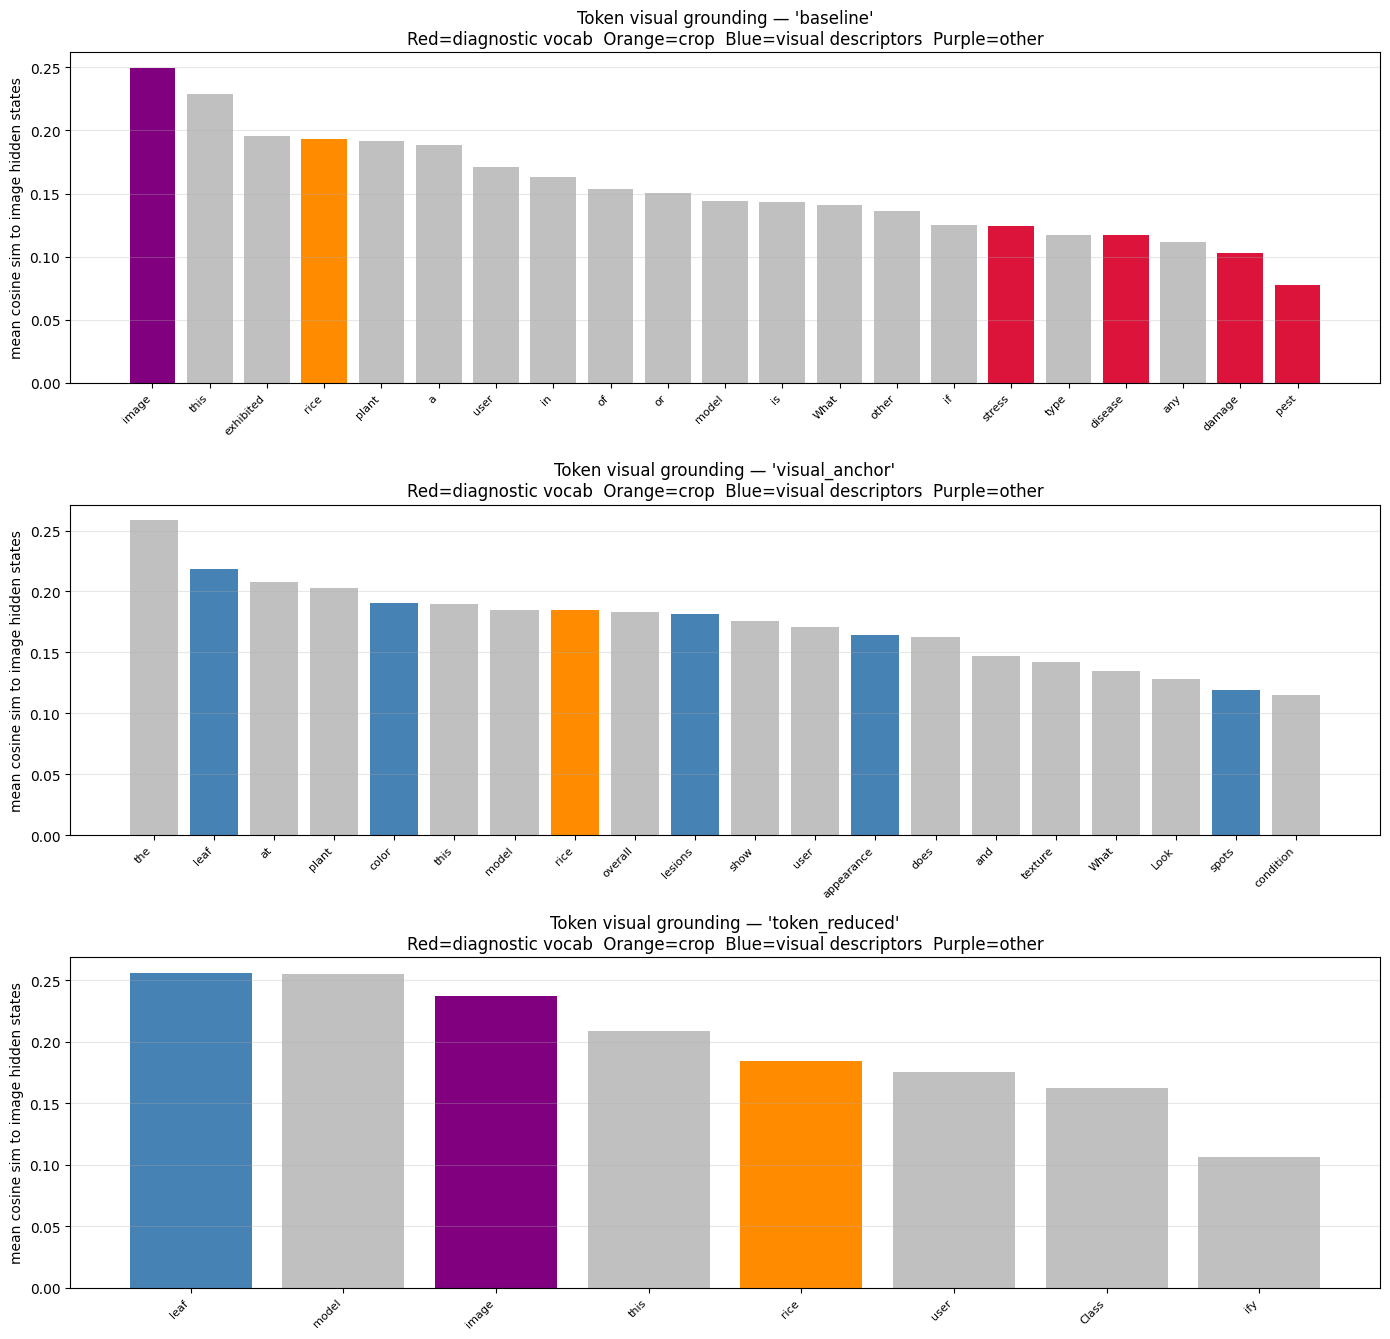


Hidden-state image similarity — key tokens across prompts:
token                   baseline         visual_anchor    token_reduced  
-------------------------------------------------------------------------
▁disease                         0.1173              nan              nan
▁pest                            0.0777              nan              nan
▁stress                          0.1242              nan              nan
▁rice                            0.1934           0.1847           0.1844
▁Rice                               nan              nan              nan
▁leaf                               nan           0.2187           0.2560
▁color                              nan           0.1909              nan
▁spots                              nan           0.1192              nan
▁Classify                           nan              nan              nan
▁image                           0.2497              nan           0.2374

── Hypothesis check ───────────────────────────────

In [17]:
# Plot mean hidden-state image similarity per token for each prompt

HIGHLIGHT_TOKENS = {
    "▁disease":    "crimson",
    "▁pest":       "crimson",
    "▁stress":     "crimson",
    "▁damage":     "crimson",
    "▁rice":       "darkorange",
    "▁Rice":       "darkorange",
    "▁leaf":       "steelblue",
    "▁color":      "steelblue",
    "▁spots":      "steelblue",
    "▁lesions":    "steelblue",
    "▁appearance": "steelblue",
    "▁Classify":   "purple",
    "▁image":      "purple",
}

fig, axes = plt.subplots(len(ANALYSIS_PROMPTS), 1,
                          figsize=(14, 4.5 * len(ANALYSIS_PROMPTS)))
if len(ANALYSIS_PROMPTS) == 1: axes = [axes]

for ax, prompt_name in zip(axes, ANALYSIS_PROMPTS):
    tok_means = {t: np.mean(v) for t, v in sim_results[prompt_name].items() if len(v) >= 2}
    if not tok_means:
        ax.set_title(f"{prompt_name} — no data"); continue

    sorted_toks = sorted(tok_means, key=tok_means.get, reverse=True)[:40]
    vals   = [tok_means[t] for t in sorted_toks]
    labels = [t.replace("▁", "") for t in sorted_toks]
    colors = [HIGHLIGHT_TOKENS.get(t, "silver") for t in sorted_toks]

    ax.bar(range(len(labels)), vals, color=colors)
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=8)
    ax.set_ylabel("mean cosine sim to image hidden states")
    ax.set_title(
        f"Token visual grounding — '{prompt_name}'\n"
        f"Red=diagnostic vocab  Orange=crop  Blue=visual descriptors  Purple=other"
    )
    ax.grid(alpha=0.3, axis="y")

plt.tight_layout(); plt.show()

# Comparison table: diagnostic tokens across prompts
FOCUS_TOKS = ["▁disease", "▁pest", "▁stress", "▁rice", "▁Rice", "▁leaf",
              "▁color", "▁spots", "▁Classify", "▁image"]

print("\nHidden-state image similarity — key tokens across prompts:")
print(f"{'token':22s}", end="")
for p in ANALYSIS_PROMPTS:
    print(f"  {p:15s}", end="")
print()
print("-" * (22 + 17 * len(ANALYSIS_PROMPTS)))
for tok in FOCUS_TOKS:
    print(f"{tok:22s}", end="")
    found_any = False
    for p in ANALYSIS_PROMPTS:
        vals = sim_results[p].get(tok, [])
        val  = np.mean(vals) if vals else float("nan")
        print(f"  {val:15.4f}", end="")
        if vals: found_any = True
    print()

# Hypothesis summary
print("\n── Hypothesis check ─────────────────────────────────────────")
print("Are diagnostic tokens (red) less visually grounded than visual descriptors (blue)?")
for p in ANALYSIS_PROMPTS:
    diag_toks = ["▁disease", "▁pest", "▁stress", "▁damage"]
    vis_toks  = ["▁leaf", "▁color", "▁spots", "▁lesions", "▁appearance"]
    diag_vals = [np.mean(sim_results[p][t]) for t in diag_toks if sim_results[p].get(t)]
    vis_vals  = [np.mean(sim_results[p][t]) for t in vis_toks  if sim_results[p].get(t)]
    diag_mean = np.mean(diag_vals) if diag_vals else float("nan")
    vis_mean  = np.mean(vis_vals)  if vis_vals  else float("nan")
    gap       = vis_mean - diag_mean
    verdict   = "YES — visual descriptors more grounded" if gap > 0 else "NO — diagnostic vocab equally/more grounded"
    print(f"  {p:15s}  diag={diag_mean:.4f}  visual={vis_mean:.4f}  gap={gap:+.4f}  -> {verdict}")

## 7. Token embedding proximity to image tokens

Beyond attention weights, we can ask: in the transformer's shared embedding space,
are `disease`/`pest`/`stress` embeddings geometrically close to the image token
embeddings for diseased rice?

We extract the **input embeddings** (before any transformer layers) for both
text tokens and image tokens, then measure cosine similarity.

This is the Gemma 4 equivalent of the OWLv2 geometry analysis — but now text and
image tokens share the same embedding table, so the comparison is apples-to-apples.

In [18]:
def get_input_embeddings(image, prompt_text):
    """
    Returns input embeddings for all tokens (text + image) before transformer layers.
    Shape: (seq_len, d_model)
    """
    messages = [
        {"role": "user", "content": [
            {"type": "image", "image": image},
            {"type": "text",  "text": prompt_text},
        ]}
    ]
    text_input = processor.apply_chat_template(
        messages, add_generation_prompt=True, tokenize=False
    )
    inputs = processor(
        text=text_input, images=image, return_tensors="pt"
    ).to(device)

    input_ids = inputs["input_ids"][0]
    image_token_id = getattr(processor, "image_token_id", None)
    if image_token_id is None:
        image_token_id = processor.tokenizer.convert_tokens_to_ids(
            getattr(processor.tokenizer, "image_token", "<image>")
        )
    img_positions = (input_ids == image_token_id).nonzero(as_tuple=True)[0]

    # Get embeddings — for Gemma 4 these go through vision encoder for image tokens
    with torch.no_grad():
        embeds = model.get_input_embeddings()(inputs["input_ids"])  # (1, seq, d)
        # For image tokens, Gemma replaces with vision encoder output
        # We access the full embedded sequence via a single forward pass
        outputs = model(**inputs, output_hidden_states=True, return_dict=True)
        # layer 0 hidden states = input embeddings after positional encoding
        layer0 = outputs.hidden_states[0][0].float()  # (seq, d)

    tokens   = processor.tokenizer.convert_ids_to_tokens(input_ids.tolist())
    return layer0.cpu().numpy(), tokens, img_positions.cpu().numpy()

# Build per-class image token centroids and per-token text embeddings
print("Extracting embeddings (this takes a while)...")
baseline_prompt = format_prompt(PROMPTS["baseline"])

class_img_centroids = {}   # class -> mean image token embedding
token_embeddings    = defaultdict(list)  # token -> list of embedding vectors

N_EMBED = 8  # images per class for embedding analysis

for class_name in tqdm(DISEASE_CLASSES, desc="classes"):
    img_emb_list = []
    for idx in class_indices[class_name][:N_EMBED]:
        try:
            embs, toks, img_pos = get_input_embeddings(ds[idx]["image"], baseline_prompt)
            # Collect image token embeddings
            if len(img_pos) > 0:
                img_emb_list.append(embs[img_pos].mean(0))
            # Collect text token embeddings (first occurrence only)
            seen = set()
            for pos, tok in enumerate(toks):
                if tok not in seen and pos not in img_pos:
                    token_embeddings[tok].append(embs[pos])
                    seen.add(tok)
        except Exception as e:
            pass
    if img_emb_list:
        centroid = np.mean(img_emb_list, axis=0)
        centroid = centroid / (np.linalg.norm(centroid) + 1e-6)
        class_img_centroids[class_name] = centroid

print(f"\nBuilt centroids for {len(class_img_centroids)} classes")
print(f"Collected embeddings for {len(token_embeddings)} unique tokens")


Extracting embeddings (this takes a while)...


classes: 100%|██████████| 7/7 [00:07<00:00,  1.11s/it]


Built centroids for 7 classes
Collected embeddings for 29 unique tokens


In [19]:
# Measure cosine similarity: each text token vs each class image centroid
FOCUS_TOKENS = [
    "▁disease", "▁pest", "▁stress", "▁damage",   # diagnostic vocabulary
    "▁rice", "▁Rice",                              # crop token
    "▁leaf", "▁color", "▁spots", "▁lesions",      # visual descriptors
    "▁Healthy", "▁Blast", "▁Tungro",               # class name tokens
]

def mean_embed(tok):
    vecs = token_embeddings.get(tok, [])
    if not vecs: return None
    v = np.mean(vecs, axis=0)
    return v / (np.linalg.norm(v) + 1e-6)

rows = []
for tok in FOCUS_TOKENS:
    t_emb = mean_embed(tok)
    if t_emb is None: continue
    row = {"token": tok.replace("▁", "")}
    for class_name, c_emb in class_img_centroids.items():
        row[class_name] = float(np.dot(t_emb, c_emb))
    rows.append(row)

sim_df = pd.DataFrame(rows).set_index("token")
print("Cosine similarity: text tokens vs class image centroids")
print(sim_df.round(3).to_string())


Cosine similarity: text tokens vs class image centroids
         Healthy  Insect  Leaf Scald  Rice Blast  Rice Leaffolder  Rice Stripes  Rice Tungro
token                                                                                       
disease    0.055   0.060       0.060       0.061            0.064         0.060        0.058
pest       0.077   0.073       0.071       0.074            0.074         0.077        0.074
stress     0.060   0.054       0.051       0.059            0.059         0.057        0.059
damage     0.033   0.036       0.035       0.037            0.037         0.038        0.034
rice       0.055   0.044       0.041       0.051            0.051         0.052        0.049


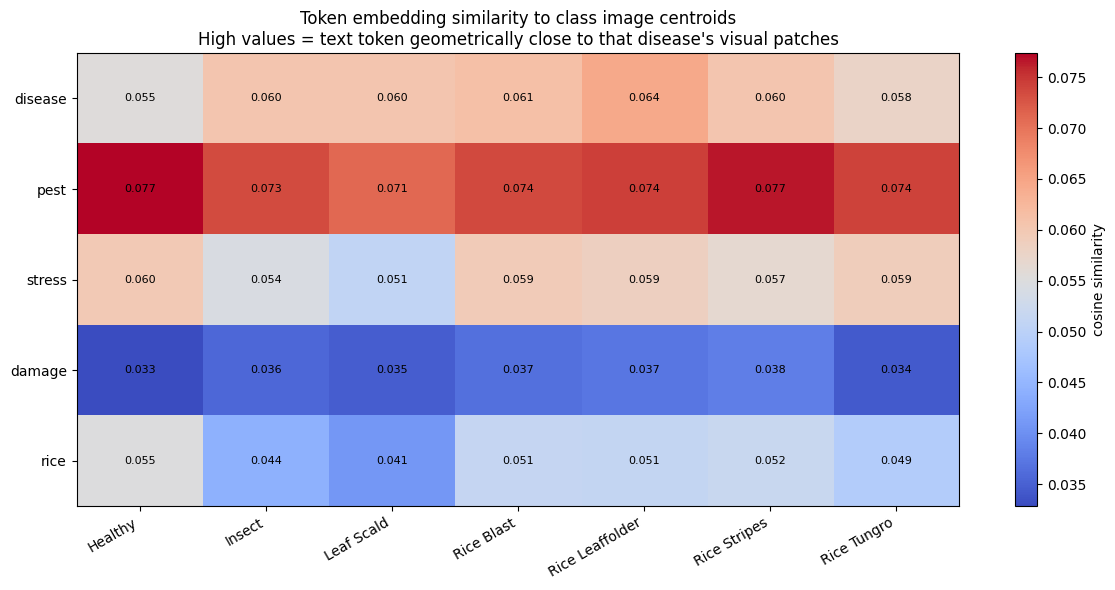


Mean similarity across all classes:
token
pest       0.0743
disease    0.0600
stress     0.0569
rice       0.0491
damage     0.0356

Hypothesis check:
If 'disease'/'pest'/'stress' have LOWER mean similarity than 'leaf'/'spots'
-> diagnostic vocabulary is less visually grounded than visual descriptors
  diagnostic tokens mean sim: 0.0567
  visual descriptor mean sim: nan
  gap: +nan  (positive = visual descriptors more grounded)


In [20]:
# Heatmap of token-image cosine similarities
fig, ax = plt.subplots(figsize=(12, 6))
im = ax.imshow(sim_df.values, aspect="auto", cmap="coolwarm",
               vmin=sim_df.values.min(), vmax=sim_df.values.max())
ax.set_xticks(range(len(sim_df.columns)))
ax.set_xticklabels(sim_df.columns, rotation=30, ha="right")
ax.set_yticks(range(len(sim_df.index)))
ax.set_yticklabels(sim_df.index)
for i in range(len(sim_df.index)):
    for j in range(len(sim_df.columns)):
        ax.text(j, i, f"{sim_df.values[i,j]:.3f}",
                ha="center", va="center", fontsize=8)
plt.colorbar(im, ax=ax, label="cosine similarity")
ax.set_title(
    "Token embedding similarity to class image centroids\n"
    "High values = text token geometrically close to that disease's visual patches"
)
plt.tight_layout(); plt.show()

# Key comparison: diagnostic tokens vs visual descriptor tokens vs class name tokens
print("\nMean similarity across all classes:")
print(sim_df.mean(axis=1).sort_values(ascending=False).round(4).to_string())
print()
print("Hypothesis check:")
print("If 'disease'/'pest'/'stress' have LOWER mean similarity than 'leaf'/'spots'")
print("-> diagnostic vocabulary is less visually grounded than visual descriptors")
diag_mean = sim_df.loc[[t for t in ["disease","pest","stress","damage"] if t in sim_df.index]].mean().mean()
vis_mean  = sim_df.loc[[t for t in ["leaf","color","spots","lesions"] if t in sim_df.index]].mean().mean()
print(f"  diagnostic tokens mean sim: {diag_mean:.4f}")
print(f"  visual descriptor mean sim: {vis_mean:.4f}")
print(f"  gap: {vis_mean - diag_mean:+.4f}  (positive = visual descriptors more grounded)")


## 8. PCA visualization of the shared embedding space

Project text token embeddings and class image token centroids into 2D.
This shows intuitively whether diagnostic tokens cluster separately from
image tokens — the visual analog of the 3Blue1Brown vector picture.

Unlike OWLv2 where text and image were in different towers, here everything
is in one space, so this PCA is directly meaningful.

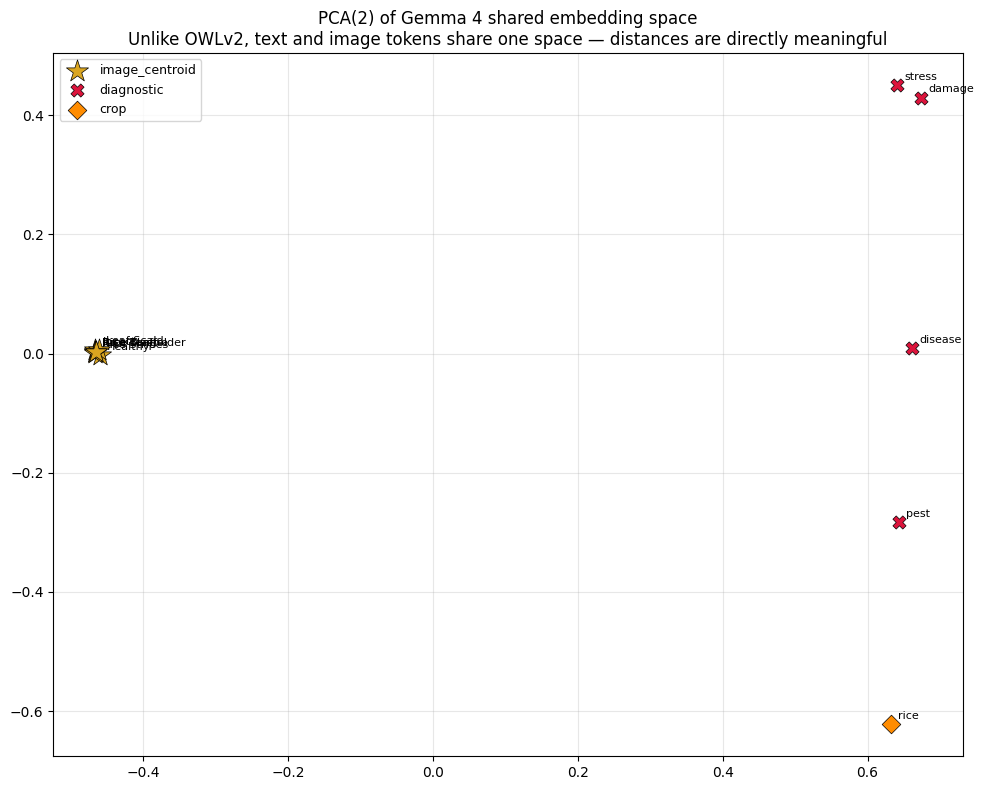

In [21]:
# Collect all vectors for PCA
pca_vecs, pca_labels, pca_types = [], [], []

# Image centroids
for class_name, c_emb in class_img_centroids.items():
    pca_vecs.append(c_emb); pca_labels.append(class_name); pca_types.append("image_centroid")

# Text token mean embeddings — all focus tokens
for tok in FOCUS_TOKENS:
    t_emb = mean_embed(tok)
    if t_emb is not None:
        pca_vecs.append(t_emb)
        pca_labels.append(tok.replace("▁",""))
        if tok in ("▁disease","▁pest","▁stress","▁damage"):
            pca_types.append("diagnostic")
        elif tok in ("▁rice","▁Rice"):
            pca_types.append("crop")
        elif tok in ("▁leaf","▁color","▁spots","▁lesions"):
            pca_types.append("visual_descriptor")
        else:
            pca_types.append("class_name")

pca_vecs = np.array(pca_vecs)
pca = PCA(n_components=2).fit(pca_vecs)
P   = pca.transform(pca_vecs)

type_styles = {
    "image_centroid":   ("*",  280, "goldenrod"),
    "diagnostic":       ("X",   90, "crimson"),
    "crop":             ("D",   90, "darkorange"),
    "visual_descriptor":("s",   80, "steelblue"),
    "class_name":       ("^",   80, "purple"),
}

fig, ax = plt.subplots(figsize=(10, 8))
for ptype, (marker, size, color) in type_styles.items():
    mask = [i for i, t in enumerate(pca_types) if t == ptype]
    if not mask: continue
    pts = P[mask]
    ax.scatter(pts[:,0], pts[:,1], marker=marker, s=size,
               color=color, edgecolors="k" if ptype != "image_centroid" else "k",
               linewidths=0.5, label=ptype, zorder=4)
    for i in mask:
        ax.annotate(pca_labels[i], P[i],
                    xytext=(5, 4), textcoords="offset points", fontsize=8)

ax.set_title(
    "PCA(2) of Gemma 4 shared embedding space\n"
    "Unlike OWLv2, text and image tokens share one space — distances are directly meaningful"
)
ax.legend(loc="best", fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()


## 9. Summary and interpretation

### What to look for

**Section 5 (accuracy):**
- Does removing `disease`/`pest`/`stress` vocabulary hurt or help accuracy?
- Does `visual_anchor` (explicit visual descriptors) outperform `baseline`?
- Which class is hardest regardless of prompt? (Likely visually ambiguous ones like `Insect`)

**Section 6 (attention):**
- Do `disease`/`pest`/`stress` tokens attend weakly to image tokens compared to
  `leaf`/`spots`/`lesions`? If yes → your hypothesis confirmed: diagnostic vocabulary
  is not visually grounded, it's floating in abstract semantic space.
- Does the `rice` crop token have notably higher image attention than `disease`?
  If yes → crop tokens serve as visual anchors; disease vocabulary does not.
- Do answer tokens (the actual class names in the output) show very high image attention?
  They should — they're the tokens that actually read the image.

**Section 7 (embedding proximity):**
- Are class-name tokens (`Blast`, `Tungro`, `Leaffolder`) closer to their class's
  image centroid than generic diagnostic tokens (`disease`, `stress`)?
  If yes → the model has learned class-specific visual grounding for the answer vocabulary,
  but not for the question vocabulary.
- Is `rice` closer to rice plant image tokens than `disease`? Expected yes.

**Section 8 (PCA):**
- Do diagnostic tokens cluster separately from image centroids?
  The modality gap we saw in OWLv2 (text and image in different hemispheres) may
  partially persist here even in the unified space, just smaller.

### The actionable finding
If `disease`/`pest`/`stress` attend weakly to image tokens AND sit far from disease
image centroids, then those tokens are *wasted* in your prompt — they're not
contributing to visual retrieval. The prompt could be shortened or replaced with
visual descriptors without losing (and possibly gaining) accuracy.

The ideal next step would be to do what the OWLv2 paper did: systematically swap
each "weakly grounded" token for alternatives that have higher image-token cosine,
run accuracy on that variant, and measure whether the grounding improvement
translates to better classification.

In [22]:
# For each disease class centroid, find top-K nearest tokens in vocabulary
def find_nearest_vocab_tokens(class_centroid, top_k=20):
    """
    Search the full embedding table for tokens whose hidden-state
    representation is closest to the class image centroid.
    """
    # Get full embedding matrix: (vocab_size, d)
    embed_matrix = model.get_input_embeddings().weight.detach().float().cpu()
    norms = embed_matrix.norm(dim=-1, keepdim=True).clamp(min=1e-6)
    embed_norm = embed_matrix / norms                    # (vocab, d)
    
    centroid = torch.tensor(class_centroid, dtype=torch.float32)
    centroid = centroid / (centroid.norm() + 1e-6)
    
    sims = embed_norm @ centroid                         # (vocab,)
    top_ids = sims.argsort(descending=True)[:top_k]
    top_toks = processor.tokenizer.convert_ids_to_tokens(top_ids.tolist())
    top_vals = sims[top_ids].numpy()
    return list(zip(top_toks, top_vals))

for class_name, centroid in class_img_centroids.items():
    nearest = find_nearest_vocab_tokens(centroid, top_k=15)
    # Filter to readable tokens only
    readable = [(t.replace("▁",""), v) for t,v in nearest 
                if t.replace("▁","").isalpha() and len(t.replace("▁","")) > 2][:8]
    print(f"\n{class_name}:")
    for tok, val in readable:
        print(f"  '{tok}'  sim={val:.4f}")


Healthy:
  'gust'  sim=0.1169
  'sturdy'  sim=0.1123
  'amazingly'  sim=0.1100
  'exceedingly'  sim=0.1091
  'strikingly'  sim=0.1065

Insect:
  'gust'  sim=0.1144
  'sturdy'  sim=0.1053
  'older'  sim=0.1038
  'drooping'  sim=0.1034

Leaf Scald:
  'gust'  sim=0.1121
  'sturdy'  sim=0.1090
  'ortho'  sim=0.1057

Rice Blast:
  'gust'  sim=0.1173
  'older'  sim=0.1047
  'amazingly'  sim=0.1046
  'sturdy'  sim=0.1032

Rice Leaffolder:
  'gust'  sim=0.1147
  'older'  sim=0.1097
  'sturdy'  sim=0.1089
  'exceedingly'  sim=0.1073
  'fungi'  sim=0.1053

Rice Stripes:
  'gust'  sim=0.1156
  'sturdy'  sim=0.1115
  'ortho'  sim=0.1059
  'exceedingly'  sim=0.1055

Rice Tungro:
  'gust'  sim=0.1132
  'older'  sim=0.1072
  'sturdy'  sim=0.1060
  'amazingly'  sim=0.1035


In [23]:
def find_discriminative_tokens(target_class, all_centroids, top_k=10, min_gap=0.005):
    """
    Find vocab tokens that are closest to target_class centroid
    AND maximally far from all other class centroids.
    This finds tokens that discriminate, not just tokens that are 
    near agricultural images generally.
    """
    embed_matrix = model.get_input_embeddings().weight.detach().float().cpu()
    norms = embed_matrix.norm(dim=-1, keepdim=True).clamp(min=1e-6)
    embed_norm = embed_matrix / norms   # (vocab, d)

    # Similarity to target class
    target_c = torch.tensor(all_centroids[target_class], dtype=torch.float32)
    target_c = target_c / (target_c.norm() + 1e-6)
    sim_target = embed_norm @ target_c   # (vocab,)

    # Mean similarity to all OTHER classes
    other_sims = []
    for class_name, centroid in all_centroids.items():
        if class_name == target_class: continue
        c = torch.tensor(centroid, dtype=torch.float32)
        c = c / (c.norm() + 1e-6)
        other_sims.append(embed_norm @ c)
    sim_others = torch.stack(other_sims).mean(0)   # (vocab,)

    # Discriminability = similarity to target MINUS mean similarity to others
    discriminability = sim_target - sim_others      # (vocab,)

    top_ids = discriminability.argsort(descending=True)[:top_k * 5]
    top_toks = processor.tokenizer.convert_ids_to_tokens(top_ids.tolist())
    top_disc = discriminability[top_ids].numpy()
    top_sim  = sim_target[top_ids].numpy()

    readable = [
        (t.replace("▁",""), float(d), float(s))
        for t, d, s in zip(top_toks, top_disc, top_sim)
        if t.replace("▁","").isalpha() and len(t.replace("▁","")) > 2
    ][:top_k]
    return readable

print("Discriminative tokens per class (nearest to THIS class, farthest from others):\n")
discriminative_vocab = {}
for class_name in DISEASE_CLASSES:
    tokens = find_discriminative_tokens(class_name, class_img_centroids)
    discriminative_vocab[class_name] = tokens
    print(f"{class_name}:")
    for tok, disc, sim in tokens:
        print(f"  '{tok:15s}'  discriminability={disc:+.4f}  sim_to_class={sim:.4f}")
    print()

Discriminative tokens per class (nearest to THIS class, farthest from others):

Healthy:
  'condensation   '  discriminability=+0.0175  sim_to_class=0.0722
  'powdered       '  discriminability=+0.0162  sim_to_class=0.0807
  'itzel          '  discriminability=+0.0158  sim_to_class=0.0481
  'createArticle  '  discriminability=+0.0156  sim_to_class=0.0005
  'Xiv            '  discriminability=+0.0154  sim_to_class=0.0029
  'Encript        '  discriminability=+0.0154  sim_to_class=-0.0030
  'polished       '  discriminability=+0.0153  sim_to_class=0.0669
  'čist           '  discriminability=+0.0153  sim_to_class=0.0513
  'seite          '  discriminability=+0.0152  sim_to_class=0.0550
  'اديم           '  discriminability=+0.0152  sim_to_class=0.0270

Insect:
  'выступления    '  discriminability=+0.0116  sim_to_class=0.0369
  'hole           '  discriminability=+0.0115  sim_to_class=0.0484
  'landmarks      '  discriminability=+0.0113  sim_to_class=0.0307
  'markUp         '  discrimin

In [29]:
def build_discriminative_prompt(class_name, disc_tokens, n_tokens=3):
    top_toks = [t for t, d, s in disc_tokens[:n_tokens]]
    token_str = ", ".join(top_toks)
    return (
        f"This image of a rice plant may show characteristics such as: {token_str}. "
        f"What disease, pest, damage type, or other stress, if any, is exhibited?"
    )

print("Class-specific discriminative prompts:\n")
for class_name in DISEASE_CLASSES:
    prompt = build_discriminative_prompt(
        class_name, discriminative_vocab[class_name]
    )
    print(f"{class_name}:")
    print(f"  {prompt}")
    print()

Class-specific discriminative prompts:

Healthy:
  This image of a rice plant may show characteristics such as: condensation, powdered, itzel. What disease, pest, damage type, or other stress, if any, is exhibited?

Insect:
  This image of a rice plant may show characteristics such as: выступления, hole, landmarks. What disease, pest, damage type, or other stress, if any, is exhibited?

Leaf Scald:
  This image of a rice plant may show characteristics such as: Rehab, Rehabilitation, Antique. What disease, pest, damage type, or other stress, if any, is exhibited?

Rice Blast:
  This image of a rice plant may show characteristics such as: mmol, xxxx, бук. What disease, pest, damage type, or other stress, if any, is exhibited?

Rice Leaffolder:
  This image of a rice plant may show characteristics such as: clings, fény, grainy. What disease, pest, damage type, or other stress, if any, is exhibited?

Rice Stripes:
  This image of a rice plant may show characteristics such as: Grass, Pern, 

In [30]:
# Build discriminative prompts for each class and run hidden state similarity
# Then compare against baseline prompt

DISC_PROMPTS = {}
for class_name in DISEASE_CLASSES:
    DISC_PROMPTS[class_name] = build_discriminative_prompt(
        class_name, discriminative_vocab[class_name]
    )

# Collect hidden state similarity for discriminative prompts
# Key difference: each class now has its OWN prompt, so we run per-class
disc_sim_results = defaultdict(lambda: defaultdict(list))
# disc_sim_results[class_name][token] = [sim values]

for class_name in tqdm(DISEASE_CLASSES, desc="classes"):
    prompt_text = DISC_PROMPTS[class_name]
    indices = class_indices[class_name][:N_ATTN]
    for idx in indices:
        img = ds[idx]["image"]
        try:
            sims, txt_toks, _ = get_hidden_state_image_similarity(img, prompt_text)
            for tok, sim in zip(txt_toks, sims):
                if tok not in SKIP_TOKS and tok.replace("▁","").isalpha():
                    disc_sim_results[class_name][tok].append(float(sim))
        except Exception as e:
            print(f"  skipped {class_name} idx={idx}: {e}")

print("Done. Tokens collected per class:")
for c in DISEASE_CLASSES:
    print(f"  {c:20s}: {len(disc_sim_results[c])} unique tokens")

classes: 100%|██████████| 7/7 [00:04<00:00,  1.46it/s]

Done. Tokens collected per class:
  Healthy             : 29 unique tokens
  Insect              : 28 unique tokens
  Leaf Scald          : 28 unique tokens
  Rice Blast          : 29 unique tokens
  Rice Leaffolder     : 28 unique tokens
  Rice Stripes        : 27 unique tokens
  Rice Tungro         : 29 unique tokens


Discriminative tokens injected:
  'condensation   '  class=Healthy             color=limegreen
  'powdered       '  class=Healthy             color=limegreen
  'itzel          '  class=Healthy             color=limegreen
  'выступления    '  class=Insect              color=mediumorchid
  'hole           '  class=Insect              color=mediumorchid
  'landmarks      '  class=Insect              color=mediumorchid
  'Rehab          '  class=Leaf Scald          color=deepskyblue
  'Rehabilitation '  class=Leaf Scald          color=deepskyblue
  'Antique        '  class=Leaf Scald          color=deepskyblue
  'mmol           '  class=Rice Blast          color=tomato
  'xxxx           '  class=Rice Blast          color=tomato
  'бук            '  class=Rice Blast          color=tomato
  'clings         '  class=Rice Leaffolder     color=gold
  'fény           '  class=Rice Leaffolder     color=gold
  'grainy         '  class=Rice Leaffolder     color=gold
  'Grass          '  class=Rice 

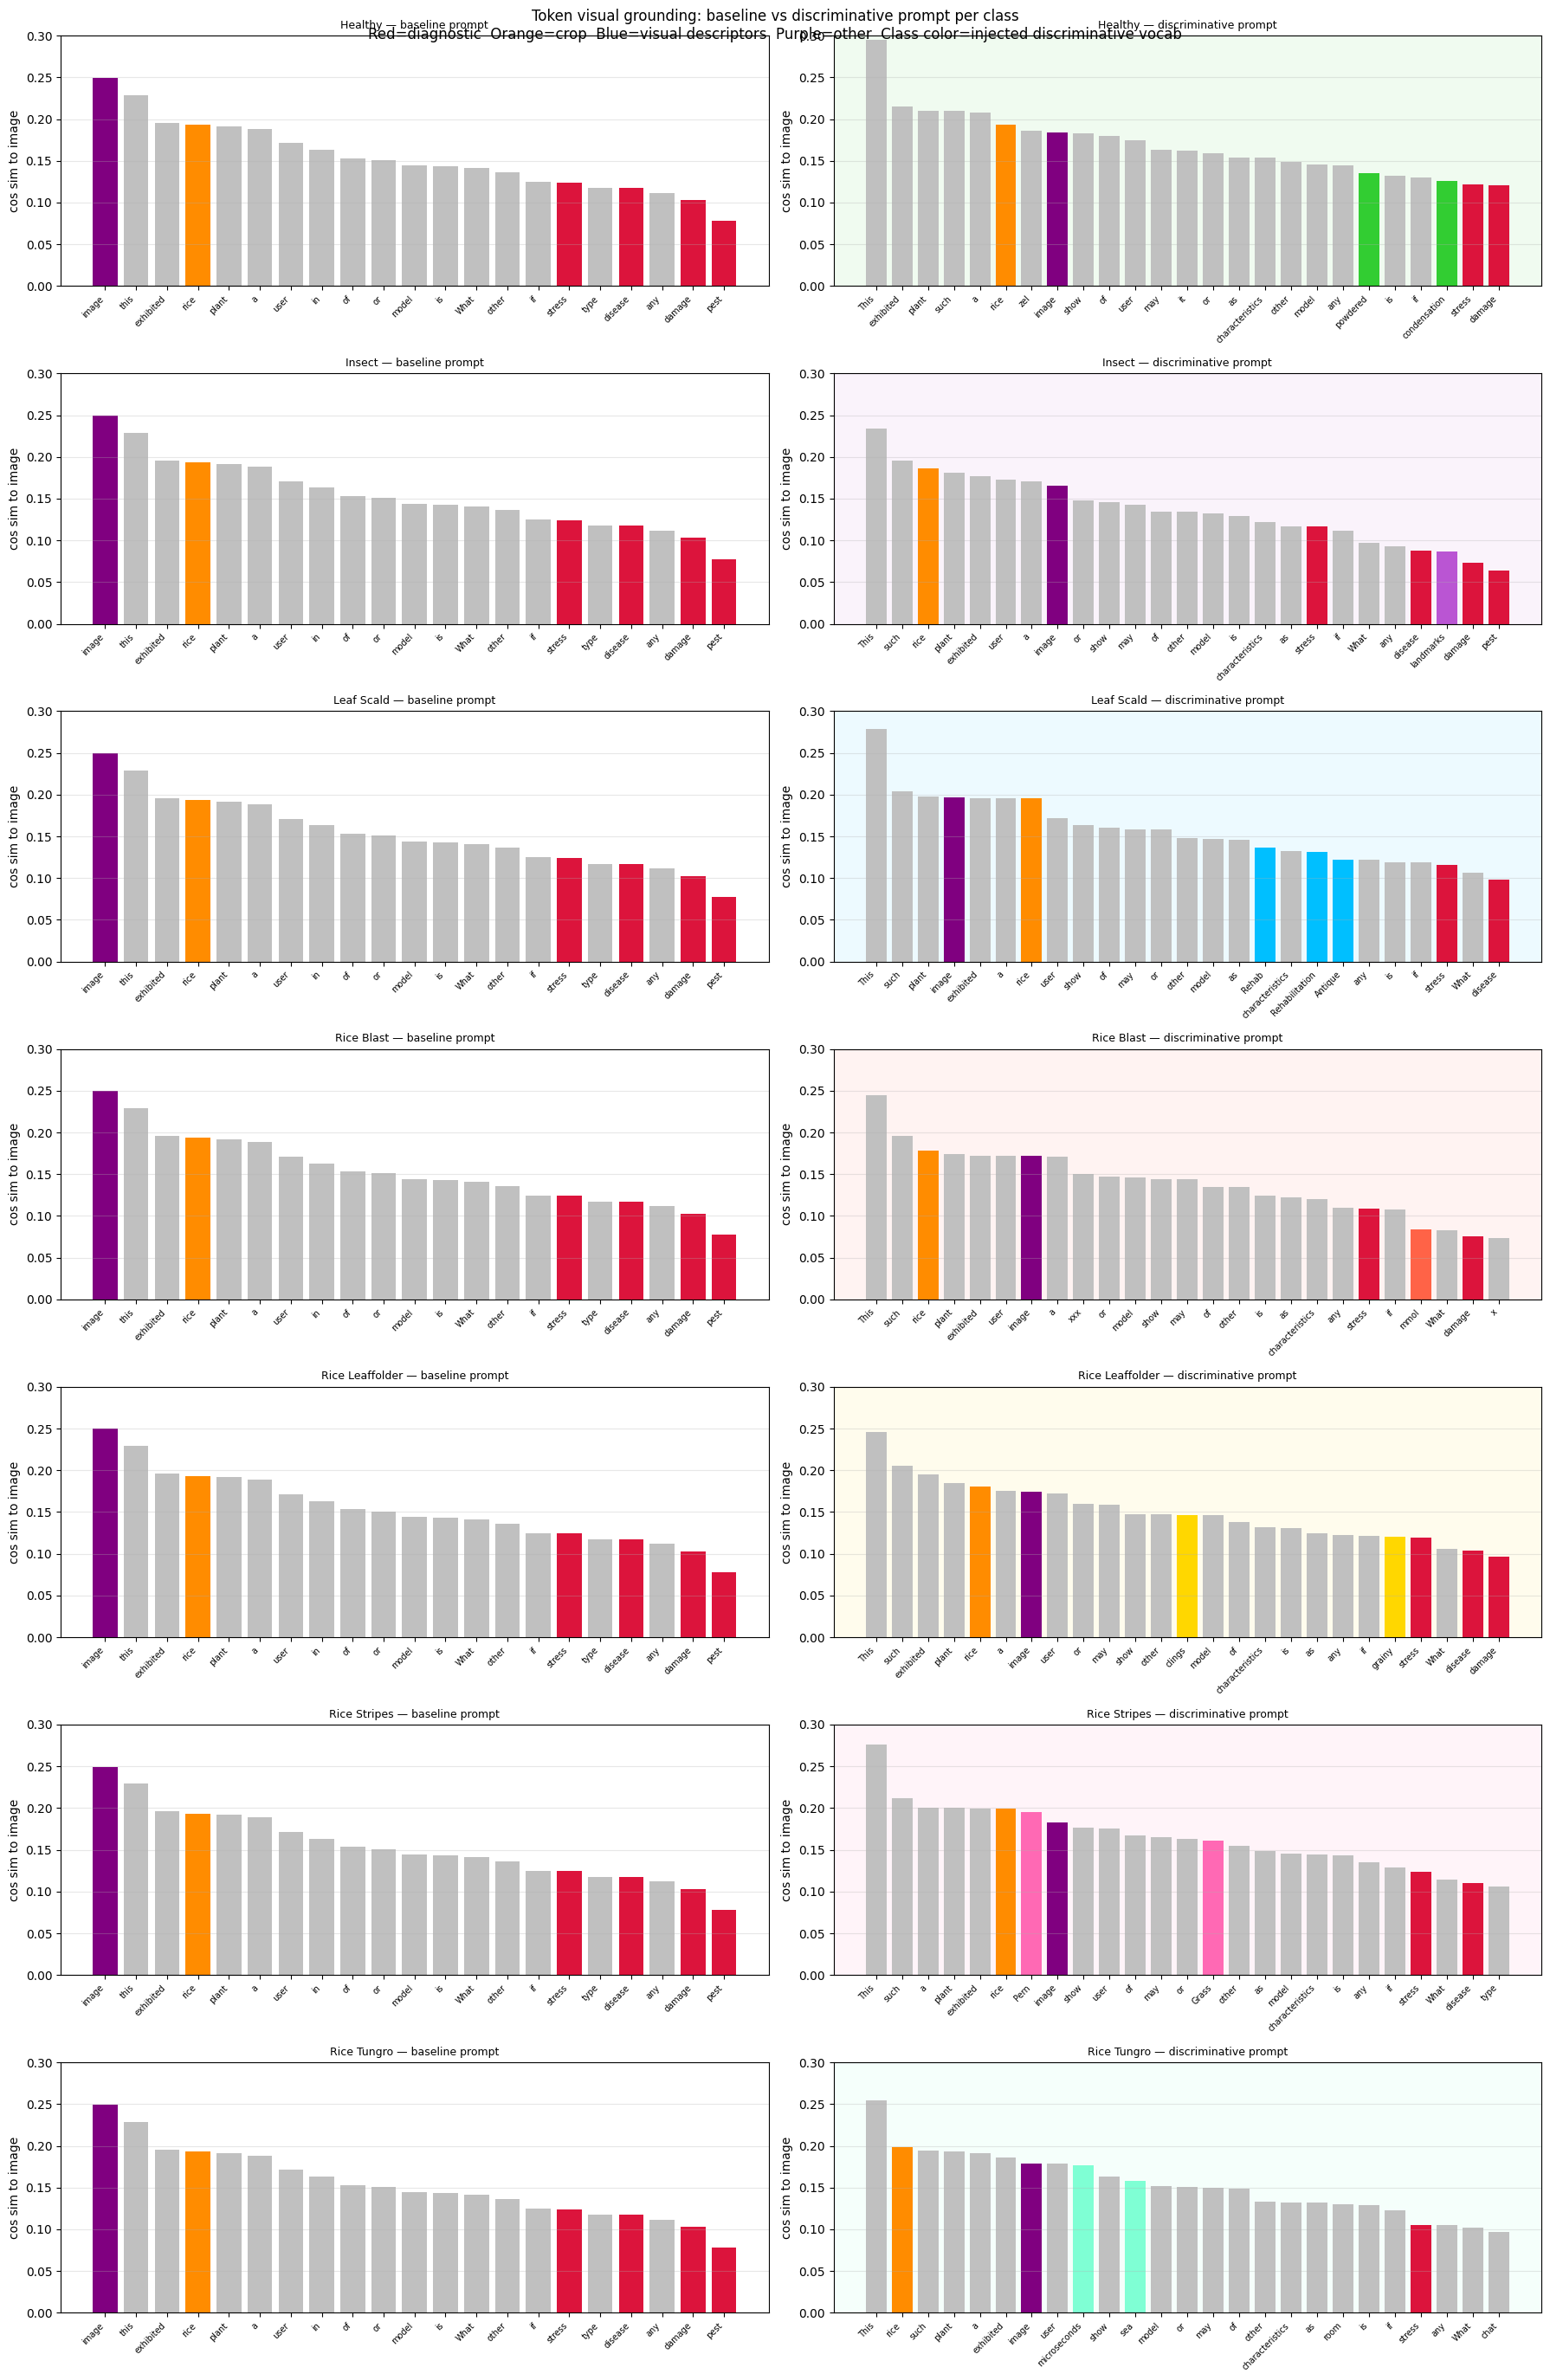

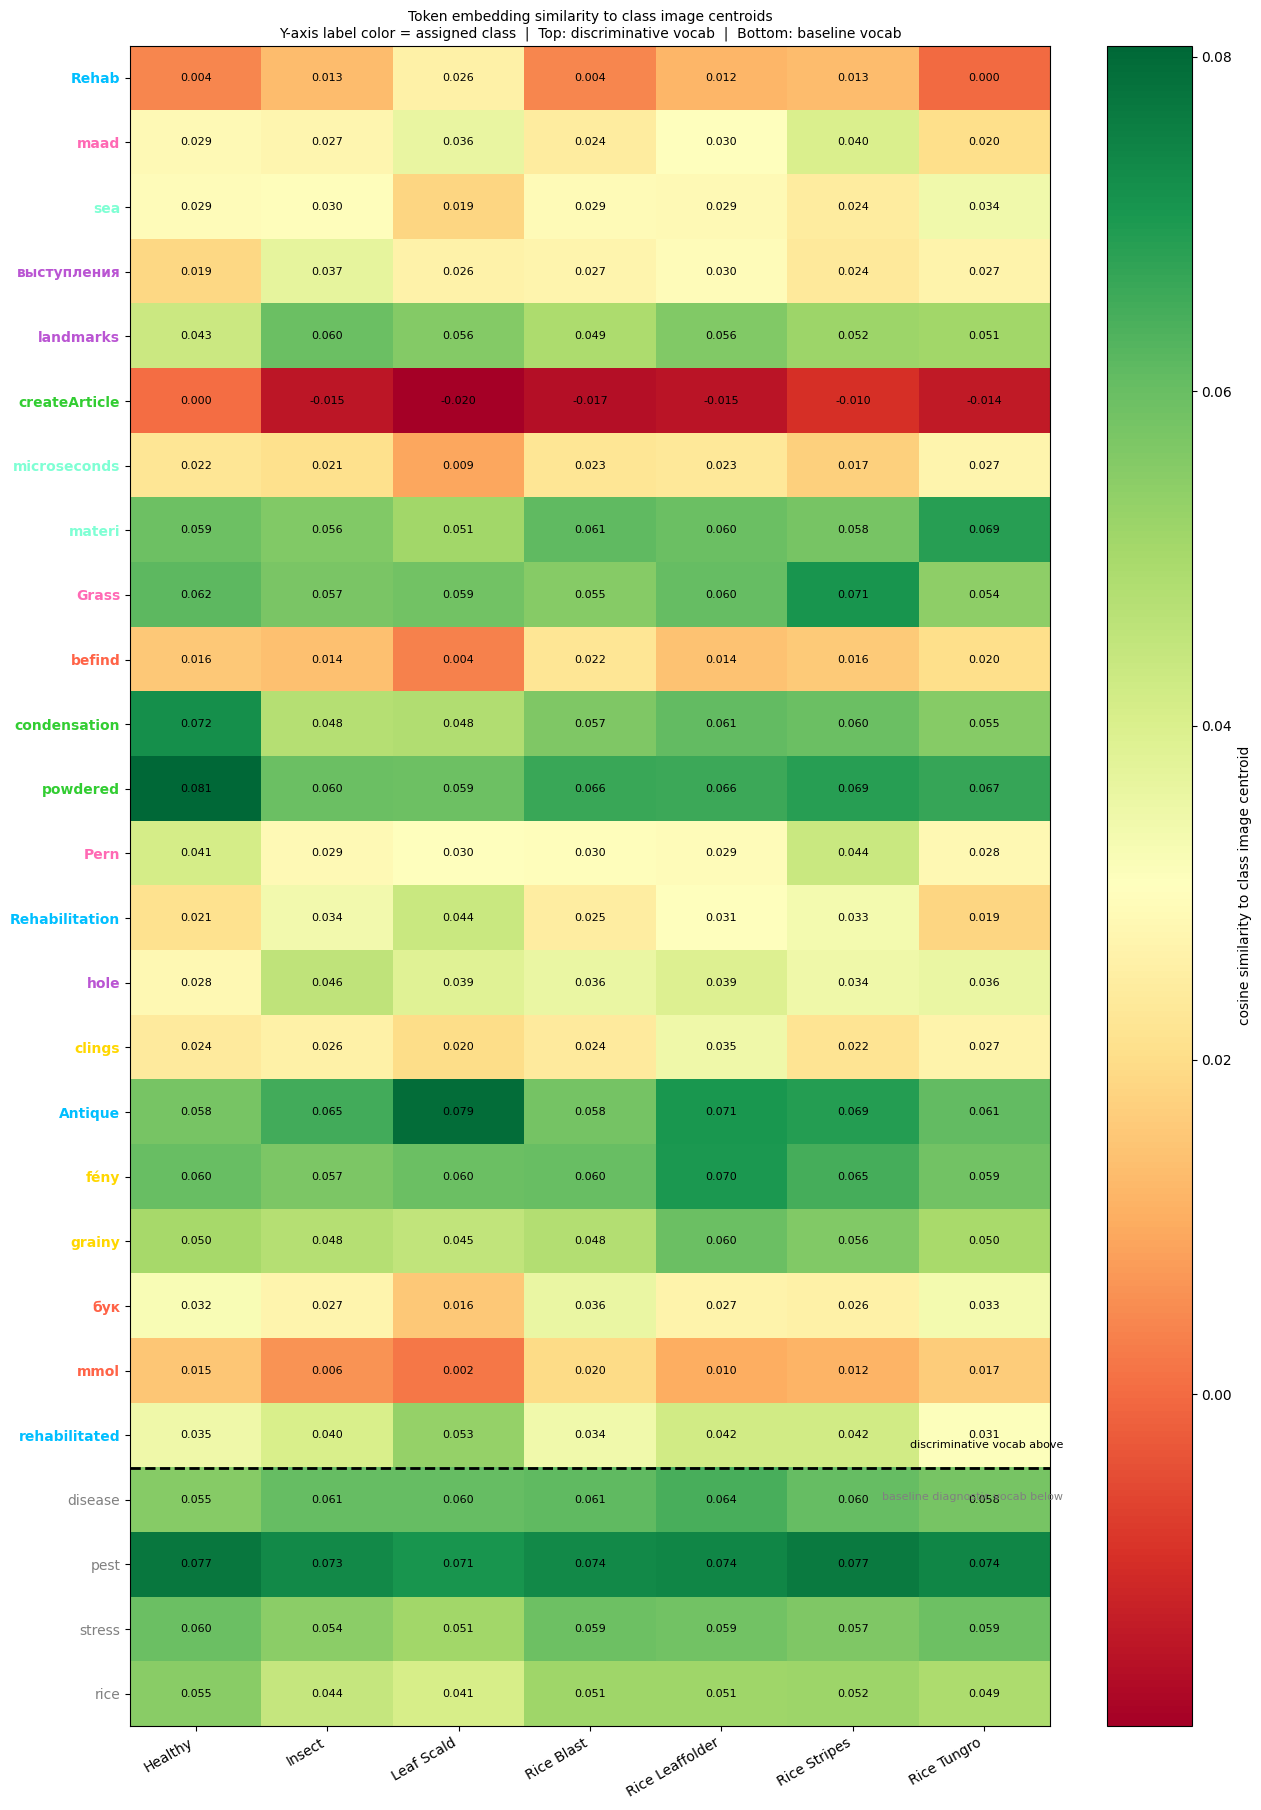

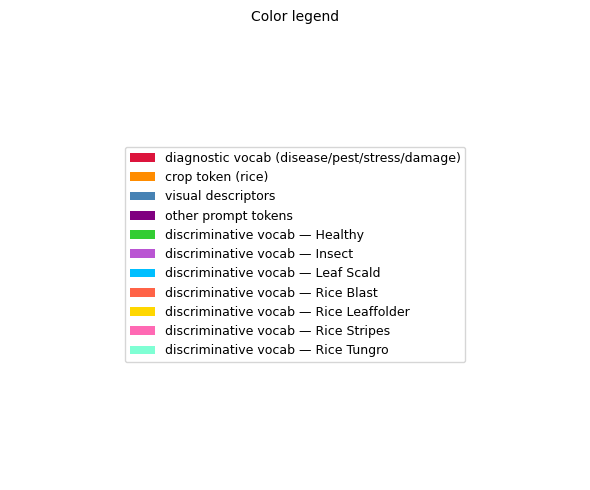


── Key comparison: discriminative vs baseline diagnostic vocab ──────
token               assigned_class      sim_to_own_class  sim_to_others_mean  discriminability
------------------------------------------------------------------------------------------
  condensation      Healthy             0.0722            0.0548              +0.0175
  powdered          Healthy             0.0807            0.0645              +0.0162
  выступления       Insect              0.0369            0.0253              +0.0116
  hole              Insect              0.0457            0.0353              +0.0104
  Rehab             Leaf Scald          0.0258            0.0080              +0.0178
  Rehabilitation    Leaf Scald          0.0436            0.0270              +0.0166
  mmol              Rice Blast          0.0198            0.0104              +0.0094
  clings            Rice Leaffolder     0.0345            0.0238              +0.0107
  fény              Rice Leaffolder     0.0701         

In [31]:
# Build HIGHLIGHT_TOKENS dynamically — discriminative tokens get a unique
# color per class so you can see exactly which new words were injected

CLASS_COLORS = {
    "Healthy":         "limegreen",
    "Insect":          "mediumorchid",
    "Leaf Scald":      "deepskyblue",
    "Rice Blast":      "tomato",
    "Rice Leaffolder": "gold",
    "Rice Stripes":    "hotpink",
    "Rice Tungro":     "aquamarine",
}

HIGHLIGHT_TOKENS = {
    "▁disease":    "crimson",   "▁pest":       "crimson",
    "▁stress":     "crimson",   "▁damage":     "crimson",
    "▁rice":       "darkorange","▁Rice":       "darkorange",
    "▁leaf":       "steelblue", "▁color":      "steelblue",
    "▁spots":      "steelblue", "▁lesions":    "steelblue",
    "▁image":      "purple",    "▁Classify":   "purple",
}

# Inject discriminative tokens with their class-specific color
disc_token_legend = {}  # tok -> (class_name, color)
for class_name in DISEASE_CLASSES:
    color = CLASS_COLORS[class_name]
    for tok, _, _ in discriminative_vocab[class_name][:3]:
        full_tok = "▁" + tok
        HIGHLIGHT_TOKENS[full_tok] = color
        disc_token_legend[tok] = (class_name, color)

print("Discriminative tokens injected:")
for tok, (cls, col) in disc_token_legend.items():
    print(f"  '{tok:15s}'  class={cls:18s}  color={col}")

# ── Chart 1: bar chart per class — baseline vs discriminative ─────────────
n_classes = len(DISEASE_CLASSES)
fig, axes = plt.subplots(n_classes, 2, figsize=(18, 4 * n_classes))

baseline_pooled = defaultdict(list)
for tok, vals in sim_results["baseline"].items():
    baseline_pooled[tok].extend(vals)

for row, class_name in enumerate(DISEASE_CLASSES):
    class_color = CLASS_COLORS[class_name]

    # Left: baseline prompt (same for all classes)
    ax_base = axes[row, 0]
    tok_means_base = {
        t: np.mean(v) for t, v in baseline_pooled.items() if len(v) >= 2
    }
    sorted_base = sorted(tok_means_base, key=tok_means_base.get, reverse=True)[:25]
    vals_b   = [tok_means_base[t] for t in sorted_base]
    labels_b = [t.replace("▁","") for t in sorted_base]
    colors_b = [HIGHLIGHT_TOKENS.get(t, "silver") for t in sorted_base]
    ax_base.bar(range(len(labels_b)), vals_b, color=colors_b)
    ax_base.set_xticks(range(len(labels_b)))
    ax_base.set_xticklabels(labels_b, rotation=45, ha="right", fontsize=7)
    ax_base.set_ylabel("cos sim to image")
    ax_base.set_title(f"{class_name} — baseline prompt", fontsize=9)
    ax_base.set_ylim(0, 0.30)
    ax_base.grid(alpha=0.3, axis="y")

    # Right: discriminative prompt (class-specific)
    ax_disc = axes[row, 1]
    tok_means_disc = {
        t: np.mean(v) for t, v in disc_sim_results[class_name].items() if len(v) >= 2
    }
    sorted_disc = sorted(tok_means_disc, key=tok_means_disc.get, reverse=True)[:25]
    vals_d   = [tok_means_disc[t] for t in sorted_disc]
    labels_d = [t.replace("▁","") for t in sorted_disc]
    colors_d = [HIGHLIGHT_TOKENS.get(t, "silver") for t in sorted_disc]
    ax_disc.bar(range(len(labels_d)), vals_d, color=colors_d)
    ax_disc.set_xticks(range(len(labels_d)))
    ax_disc.set_xticklabels(labels_d, rotation=45, ha="right", fontsize=7)
    ax_disc.set_ylabel("cos sim to image")
    ax_disc.set_title(f"{class_name} — discriminative prompt", fontsize=9)
    ax_disc.set_ylim(0, 0.30)
    ax_disc.grid(alpha=0.3, axis="y")

    # Shade right panel background with class color so it's obvious
    ax_disc.set_facecolor((*plt.matplotlib.colors.to_rgb(class_color), 0.07))

fig.suptitle(
    "Token visual grounding: baseline vs discriminative prompt per class\n"
    "Red=diagnostic  Orange=crop  Blue=visual descriptors  Purple=other  "
    "Class color=injected discriminative vocab",
    fontsize=12
)
plt.tight_layout(); plt.show()

# ── Chart 2: heatmap with discriminative token row labels colored by class ─
DISC_TOKENS_ALL = set()
for class_name in DISEASE_CLASSES:
    for tok, _, _ in discriminative_vocab[class_name][:4]:
        DISC_TOKENS_ALL.add("▁" + tok)

embed_matrix = model.get_input_embeddings().weight.detach().float().cpu()
norms_emb    = embed_matrix.norm(dim=-1, keepdim=True).clamp(min=1e-6)
embed_norm   = embed_matrix / norms_emb

rows = []
all_focus = list(DISC_TOKENS_ALL) + ["▁disease","▁pest","▁stress","▁rice"]
for tok in all_focus:
    tok_id = processor.tokenizer.convert_tokens_to_ids(tok)
    if tok_id == processor.tokenizer.unk_token_id:
        continue
    t_emb = embed_norm[tok_id]
    row = {"token": tok.replace("▁","")}
    for class_name, c_emb in class_img_centroids.items():
        c = torch.tensor(c_emb, dtype=torch.float32)
        c = c / (c.norm() + 1e-6)
        row[class_name] = float(t_emb @ c)
    rows.append(row)

disc_sim_df = pd.DataFrame(rows).set_index("token")

disc_tok_labels = [r for r in disc_sim_df.index
                   if r not in ["disease","pest","stress","rice"]]
base_tok_labels = [r for r in disc_sim_df.index
                   if r     in ["disease","pest","stress","rice"]]
ordered_index   = disc_tok_labels + base_tok_labels
disc_sim_df     = disc_sim_df.loc[ordered_index]

fig, ax = plt.subplots(figsize=(13, max(6, len(ordered_index) * 0.7)))
im = ax.imshow(disc_sim_df.values, aspect="auto", cmap="RdYlGn",
               vmin=disc_sim_df.values.min(),
               vmax=disc_sim_df.values.max())
ax.set_xticks(range(len(disc_sim_df.columns)))
ax.set_xticklabels(disc_sim_df.columns, rotation=30, ha="right")
ax.set_yticks(range(len(disc_sim_df.index)))
ax.set_yticklabels(disc_sim_df.index)

# Color each y-tick label by its assigned class
for ytick, label in zip(ax.get_yticklabels(), disc_sim_df.index):
    # Find which class this token belongs to (if any)
    matched_color = "gray"  # default for baseline diagnostic tokens
    for class_name in DISEASE_CLASSES:
        class_toks = [t for t, _, _ in discriminative_vocab[class_name][:4]]
        if label in class_toks:
            matched_color = CLASS_COLORS[class_name]
            break
    ytick.set_color(matched_color)
    ytick.set_fontweight("bold" if matched_color != "gray" else "normal")

for i in range(len(disc_sim_df.index)):
    for j in range(len(disc_sim_df.columns)):
        ax.text(j, i, f"{disc_sim_df.values[i,j]:.3f}",
                ha="center", va="center", fontsize=8)

div = len(disc_tok_labels) - 0.5
ax.axhline(div, color="black", lw=2, ls="--")
ax.text(len(disc_sim_df.columns) - 0.4, div - 0.3,
        "discriminative vocab above", fontsize=8, ha="right", color="black")
ax.text(len(disc_sim_df.columns) - 0.4, div + 0.5,
        "baseline diagnostic vocab below", fontsize=8, ha="right", color="gray")

plt.colorbar(im, ax=ax, label="cosine similarity to class image centroid")
ax.set_title(
    "Token embedding similarity to class image centroids\n"
    "Y-axis label color = assigned class  |  Top: discriminative vocab  |  Bottom: baseline vocab",
    fontsize=10
)
plt.tight_layout(); plt.show()

# ── Color legend ───────────────────────────────────────────────────────────
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor="crimson",    label="diagnostic vocab (disease/pest/stress/damage)"),
    Patch(facecolor="darkorange", label="crop token (rice)"),
    Patch(facecolor="steelblue",  label="visual descriptors"),
    Patch(facecolor="purple",     label="other prompt tokens"),
] + [
    Patch(facecolor=CLASS_COLORS[c], label=f"discriminative vocab — {c}")
    for c in DISEASE_CLASSES
]
fig_leg, ax_leg = plt.subplots(figsize=(6, 5))
ax_leg.legend(handles=legend_elements, loc="center", fontsize=9, frameon=True)
ax_leg.axis("off")
ax_leg.set_title("Color legend", fontsize=10)
plt.tight_layout(); plt.show()

# ── Summary table ──────────────────────────────────────────────────────────
print("\n── Key comparison: discriminative vs baseline diagnostic vocab ──────")
print(f"{'token':18s}  {'assigned_class':18s}  {'sim_to_own_class':16s}  "
      f"{'sim_to_others_mean':18s}  {'discriminability':16s}")
print("-" * 90)
for class_name in DISEASE_CLASSES:
    for tok, disc_val, sim_val in discriminative_vocab[class_name][:2]:
        if tok in disc_sim_df.index:
            row_vals  = disc_sim_df.loc[tok]
            own_sim   = row_vals[class_name]
            other_sim = row_vals.drop(class_name).mean()
            print(f"  {tok:16s}  {class_name:18s}  {own_sim:.4f}            "
                  f"{other_sim:.4f}              {own_sim-other_sim:+.4f}")

print()
print("Baseline diagnostic tokens for comparison:")
for tok in ["disease", "pest", "stress", "rice"]:
    if tok in disc_sim_df.index:
        row_vals   = disc_sim_df.loc[tok]
        best_class = row_vals.idxmax()
        best_sim   = row_vals.max()
        mean_sim   = row_vals.mean()
        print(f"  {tok:16s}  best={best_class:18s}  "
              f"best_sim={best_sim:.4f}  mean={mean_sim:.4f}  "
              f"disc={best_sim-mean_sim:+.4f}")

# ── Hypothesis check ───────────────────────────────────────────────────────
print("\n── Hypothesis check ──────────────────────────────────────────────────")
print("Do discriminative tokens show higher sim to their OWN class vs others?")
disc_gaps, base_gaps = [], []
for class_name in DISEASE_CLASSES:
    for tok, _, _ in discriminative_vocab[class_name][:2]:
        if tok in disc_sim_df.index:
            r = disc_sim_df.loc[tok]
            disc_gaps.append(r[class_name] - r.drop(class_name).mean())
for tok in ["disease","pest","stress"]:
    if tok in disc_sim_df.index:
        r = disc_sim_df.loc[tok]
        base_gaps.append(r.max() - r.mean())
print(f"  mean discriminability — injected tokens:  {np.mean(disc_gaps):+.4f}")
print(f"  mean discriminability — baseline vocab:   {np.mean(base_gaps):+.4f}")
verdict = "YES" if np.mean(disc_gaps) > np.mean(base_gaps) else "NO"
print(f"  Are injected tokens more class-discriminative? {verdict}")